<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/DEMO_PRAK_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Nama:** Wawa Elent Irawanti

**NIM:** 244107020192

**Kelas:** TI-3H

## Praktikum 1

### k-Nearest Neighbors (kNN)

Load Data

In [11]:
	# Load data
	import pandas as pd
	data = pd.read_csv('iris.csv')
	data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Eksplorasi Data

Cek struktur data informasi deskriptif data

In [12]:
	data.info()
	data.describe()
	data['species'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


,count
species,
setosa,50
versicolor,50
virginica,50


Visualisasi Data

Lakukan visualisasi data untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.

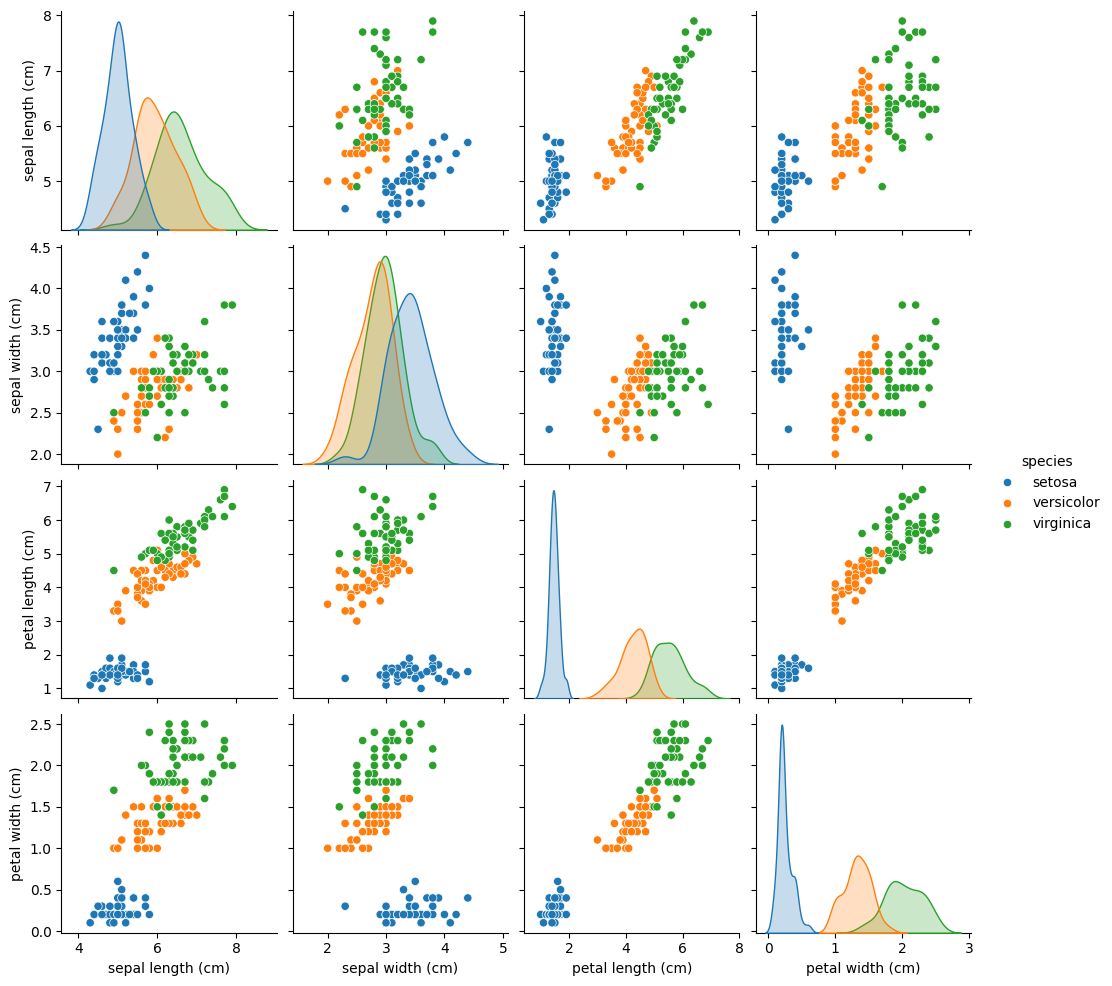

In [13]:
	import seaborn as sns
	import matplotlib.pyplot as plt

	sns.pairplot(data, hue='species')
	plt.show()

Preprocessing

Pada tahap ini, kita akan memisahkan antara label dengan fitur yang akan digunakan. Selain itu, untuk alasan pembelajaran, kita akan melakukan standardisasi dari fitur yang akan digunakan.

In [14]:
	from sklearn.model_selection import train_test_split
	from sklearn.preprocessing import StandardScaler

	X = data.iloc[:, :-1]   # semua kolom kecuali label
	y = data.iloc[:, -1]    # kolom label terakhir

	# Split data (70% train, 30% test)
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

	# Standardisasi
	scaler = StandardScaler()
	X_train = scaler.fit_transform(X_train)
	X_test = scaler.transform(X_test)

Buat Model kNN


In [15]:
	from sklearn.neighbors import KNeighborsClassifier

	# Tentukan nilai K (misalnya 3)
	knn = KNeighborsClassifier(n_neighbors=3)

	# Latih model
	knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

Evaluasi Model kNN

Pada tahap ini kita akan melakukan evaluasi terhadap model kNN yang telah dibuat sebelumnya. Metrik utama yang akan digunakan adalah akurasi dan detail analisis menggunakan confusion metrics.

In [16]:
	from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

	y_pred = knn.predict(X_test)
	print("Akurasi:", accuracy_score(y_test, y_pred))
	print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
	print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix:
 [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Dapat dilihat bahwa model dapat bekerja dengan performa sempurna pada data testing. Namun apakah memang nilai
k adalah nilai yang terbaik? Selanjutnya kita akan mengevaluasi setiap nilai
k.

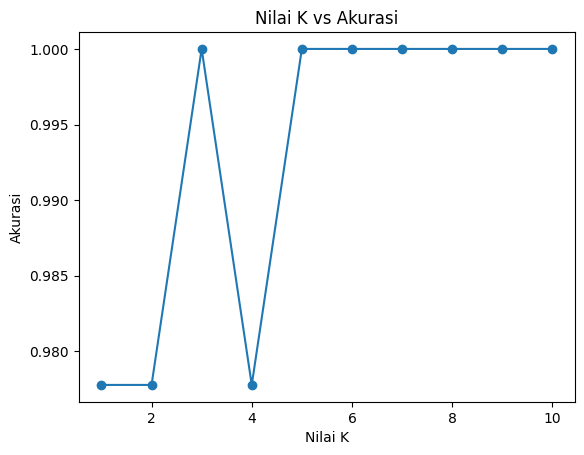

In [18]:
	acc = []
	for k in range(1, 11):
	    model = KNeighborsClassifier(n_neighbors=k)
	    model.fit(X_train, y_train)
	    acc.append(model.score(X_test, y_test))

	plt.plot(range(1, 11), acc, marker='o')
	plt.title('Nilai K vs Akurasi')
	plt.xlabel('Nilai K')
	plt.ylabel('Akurasi')
	plt.show()


## Praktikum 2

### Klasifikasi Naive Bayes dengan Data Dummy

Pada percobaan ini kita akan menggunakan data dummy (sintentis) untuk membuat sebuah model Naive Bayes. Untuk membuat data dummy, kita dapat menggunakan fungsi make_classification dari library scikit-learn. Selanjutnya, kita akan membuat model Multinomial Naive Bayes dengan menggunakan MultinomialNB dan model Gaussian Naive Bayes menggunakan GaussianNB.

Buat Dataset Dummy

In [1]:
	import numpy as np
	from sklearn.datasets import make_classification

	# Membuat data dummy
	# Hasil dari make_classification berupa data fitur X dan label y
	# Label y akan berupa data yang sudah di encode (angka)
	X,y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

	# Secara defalt, make_classfication menghasilkan nilai float
	# Kita perlu merubah dalam bentuk diskrit

	# Absolutekan nilai
	X = np.absolute(X)

	# Bulatkan nilai ke 2 angka dibelakang koma
	# Kalikan dengan 100 supaya tidak ada lagi koma
	X = np.round(X, 2) * 100

	# Ubah ke dalam bentuk integer
	X = X.astype(int)

	# Cek Hasil
	print(X)
	print(y)

[[ 88  99]
 [126 140]
 [161 244]
 [124 191]
 [ 71  26]
 [ 56  15]
 [160 254]
 [ 85  84]
 [ 10 149]
 [142 100]
 [ 37 166]
 [ 47  39]
 [ 27 130]
 [ 15 132]
 [111 100]
 [ 68 127]
 [ 37 214]
 [115 135]
 [162 166]
 [ 73 227]
 [ 22  80]
 [ 82 179]
 [115 127]
 [113  74]
 [174 171]
 [106 117]
 [ 37 110]
 [ 39  76]
 [ 60  33]
 [248 121]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


Membuat Data Frame

Agar data lebih mudah untuk dibaca, maka kita akan membuat DataFrame dengan menggunakan library Pandas berdasarkan data dummy yang telah dibuat sebelumnya.

In [2]:
	import pandas as pd

	# Reshape label y menjadi 2D
	# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
	y_new = y.reshape(len(y), 1)

	# Gabungkan fitur X dan label y dalam data array
	data = np.concatenate((X, y_new), axis=1)

	# Definisikan nama kolom
	nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

	# Buat Data Frame
	df = pd.DataFrame(data, columns=nama_kolom)

	# Cek Data Frame
	df.head()

,Fitur 1,Fitur 2,Label
0,88,99,0
1,126,140,0
2,161,244,0
3,124,191,0
4,71,26,0


Labeling

Dikarenakan label masih berbetuk encoding angka, untuk mempermudah pembacaan data, kita dapat mengubah bentuknya dalam bentuk kategorial

In [3]:
	# Definisikan nama label
	labels = {
	    1 : 'Kelas A',
	    0 : 'Kelas B'
	}

	# Copy Data Frame untuk menyimpan Data Frame baru
	# dengan label yang mudah untuk dibaca
	df_label = df.copy()

	# Ubah label dengan fungsi mapping dari Pandas
	# pada Data Frame df_label
	df_label['Label'] = df_label['Label'].map(labels)

	# Cek Data Frame df_label
	df_label.head()

,Fitur 1,Fitur 2,Label
0,88,99,Kelas B
1,126,140,Kelas B
2,161,244,Kelas B
3,124,191,Kelas B
4,71,26,Kelas B


Visualisasi Data

/tmp/ipykernel_483/1912510248.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_483/1912510248.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


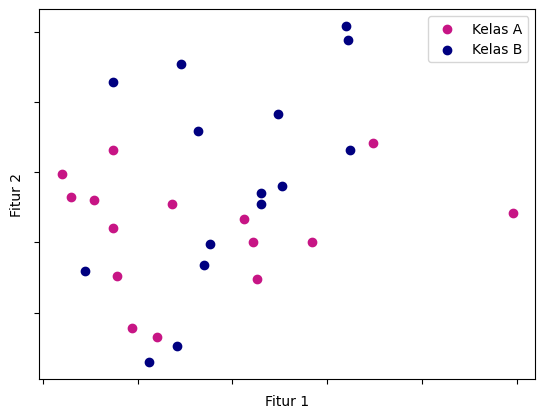

In [4]:
	import matplotlib.pyplot as plt

	# Definisikan warna untuk setiap kelas
	colors = {
	    'class_a': 'MediumVioletRed',
	    'class_b': 'Navy'
	}

	# Kelompokkan label berdasarkan nama kelas
	gb = df_label.groupby(['Label'])
	class_a = gb.get_group('Kelas A')
	class_b = gb.get_group('Kelas B')

	# Plot
	plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
	plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
	plt.xlabel('Fitur 1')
	plt.ylabel('Fitur 2')
	plt.legend(['Kelas A', 'Kelas B'])
	plt.gca().axes.xaxis.set_ticklabels([])
	plt.gca().axes.yaxis.set_ticklabels([])
	plt.show()

Model Multinomial Naive Bayes

Selanjutnya buat model naive bayes dengan jenis multinomoial. Sejatinya, model multinomial digunakan untuk fitur yang bersifat diskrit (e.g. jumlah kata untuk klasifikasi teks). Akan tetapi kita akan mencoba menggunakan model ini untuk konteks data kontinu hanya sebagai pembelajaran.

In [5]:
	from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

	# Inisiasi obyek MultinomialNB
	mnb = MultinomialNB()

	# Kita dapat langsung menggunakan fitur X dan label y
	# hasil dari proses pembuatan data dummy

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=30)

	# Fit model
	# Label y harus dalam bentuk 1D atau (n_samples,)
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred = mnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train = accuracy_score(y_train, y_train_pred)

	# Prediksi test data
	y_test_pred = mnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test = accuracy_score(y_test, y_test_pred)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.5238095238095238
Hasil akurasi data test: 0.4444444444444444


Model Gaussian Naive Bayes

Model Gaussian lebih cocok digunakan untuk data kontinu yang kita miliki, hal ini dikarenakan model ini menggunakan distribusi gaussian (normal) yang secara alami memiliki rentang dengan nilai kontinu.

In [6]:
	from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

	# Inisiasi obyek Gaussian
	gnb = GaussianNB()

	# Kita menggunakan split data training dan testing
	# yang sama dengan model multinomial

	# Fit model
	# Label y harus dalam bentu 1D atau (n_samples,)
	gnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_train_pred_gnb = gnb.predict(X_train)

	# Evaluasi akurasi training
	acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

	# Prediksi test data
	y_test_pred_gnb = gnb.predict(X_test)

	# Evaluasi model dengan metric akurasi
	acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
	print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8571428571428571
Hasil akurasi data test (Gaussian): 0.3333333333333333


Meskipun hasilnya tidak jauh berbeda dengan model multimodal, secara teoritis kita telah menerapkan langkah yang benar dalam membuat sebuah model klasifikasi dengan menggunakan Naive Bayes.

## Praktikum 3

### Klasifikasi Naive Bayes dengan Data Multimoda

Load Data

Pada tahap ini kita akan loading data ke dalam data frame dan melakukan inspeksi sederhana untuk memastikan apakah kita perlu proses pra pengolahan data sebelum melakukan ekstraksi fitur dan permodelan.

In [7]:
	import numpy as np
	import pandas as pd

	df = pd.read_csv('spam.csv', encoding='latin-1') # spesifiksi encoding diperlukan karena data tidak menggunakan UTF-8

	df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Terdapat 3 kolom yang tidak bermanfaat untuk proses selanjutnya, maka kita perlu membuang kolom tersebut. Selain itu, untuk memudahkan pembacaan data, kita juga akan mengubah nama kolom v1 yang berupa label dan v2 yang berupa teks sms.

Preprocessing

a - Drop Kolom

In [8]:
	# Drop 3 kolom terakhir dengan fungsi iloc
	df = df.drop(df.iloc[:,2:], axis=1)

	# Cek data
	df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


b - Inspeksi Data

In [13]:
	# Cek Jumlah Data Per Kelas
	print(df['Labels'].value_counts())
	print('\n')

	# Cek Kelengkapan Data
	print(df.info())
	print('\n')

	# Cek Statistik Deskriptif
	print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None


       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


c - Encoding Label

In [14]:
	# Data untuk label
	new_labels = {
	    'spam': 1,
	    'ham': 0
	}

	# Encode label
	df['Labels'] = df['Labels'].map(new_labels)

	# Cek data
	df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


d - Pisahkan Fitur dengan Label

In [15]:
	X = df['SMS'].values
	y = df['Labels'].values

Ekstraksi Fitur

Ekstraksi fitur untuk setiap SMS akan menggunakan konsep Bag of Words. Kita dapat menggunakan fungsi CountVectorizer dari scikit-learn. Akan tetapi untuk mencegah leaking information kita akan melakukan split data terlebih dahulu, baru melakukan transformasi terhadap data training dan testing.

In [16]:
	from sklearn.model_selection import train_test_split
	from sklearn.feature_extraction.text import CountVectorizer

	# Split data training dan testing
	X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

	# Inisiasi CountVectorizer
	bow = CountVectorizer()

	# Fitting dan transform X_train dengan CountVectorizer
	X_train = bow.fit_transform(X_train)

	# Transform X_test
	# Mengapa hanya transform? Alasan yang sama dengan kasus pada percobaan ke-3
	# Kita tidak menginginkan model mengetahui paramter yang digunakan oleh CountVectorizer untuk fitting data X_train
	# Sehingga, data testing dapat tetap menjadi data yang asing bagi model nantinya
	X_test = bow.transform(X_test)

Cek fitur dari proses CountVectorizer.

In [23]:
print(len(bow.get_feature_names_out()))
print(f'Dimensi data: {X_train.shape}')

7727
Dimensi data: (4457, 7727)


Training dan Evaluasi Model

Kita akan menggunakan algoritma Multinomial Naive Bayes. Fungsi MultinomialNB dari scikit-learn dapat digunakan pada kasus ini.

In [20]:
	from sklearn.naive_bayes import MultinomialNB
	from sklearn.metrics import accuracy_score

	# Inisiasi MultinomialNB
	mnb = MultinomialNB()

	# Fit model
	mnb.fit(X_train, y_train)

	# Prediksi dengan data training
	y_pred_train = mnb.predict(X_train)

	# Evaluasi akurasi data training
	acc_train = accuracy_score(y_train, y_pred_train)

	# Prediksi dengan data training
	y_pred_test = mnb.predict(X_test)

	# Evaluasi akurasi data training
	acc_test = accuracy_score(y_test, y_pred_test)

	# Print hasil evaluasi
	print(f'Hasil akurasi data train: {acc_train}')
	print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test: 0.9775784753363229


## Tugas 1

Load dataset

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset
data = pd.read_csv('/content/voice.csv')

# Menghapus spasi pada nama kolom jika ada
data.columns = data.columns.str.strip()

# Menampilkan lima data pertama
display(data.head())

# Melihat ukuran dataset
print("Ukuran dataset:", data.shape)

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Ukuran dataset: (3168, 21)


Eksplorasi data

Periksa nama kolom, tipe data, nilai kosong, dan jumlah data pada masing-masing kelas suara.

In [25]:
# Melihat struktur dan tipe data
data.info()

# Memeriksa nilai kosong
print("\nJumlah nilai kosong:")
print(data.isnull().sum().sum())

# Melihat jumlah data setiap kelas
print("\nJumlah data berdasarkan label:")
print(data['label'].value_counts())

# Statistik deskriptif
display(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  label     3168 non-null   obje

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,mode,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx
count,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000,3168.000000
mean,0.180907,0.057126,0.185621,0.140456,0.224765,0.084309,3.140168,36.568461,0.895127,0.408216,0.165282,0.180907,0.142807,0.036802,0.258842,0.829211,0.052647,5.047277,4.994630,0.173752
std,0.029918,0.016652,0.036360,0.048680,0.023639,0.042783,4.240529,134.928661,0.044980,0.177521,0.077203,0.029918,0.032304,0.019220,0.030077,0.525205,0.063299,3.521157,3.520039,0.119454
min,0.039363,0.018363,0.010975,0.000229,0.042946,0.014558,0.141735,2.068455,0.738651,0.036876,0.000000,0.039363,0.055565,0.009775,0.103093,0.007812,0.004883,0.007812,0.000000,0.000000
25%,0.163662,0.041954,0.169593,0.111087,0.208747,0.042560,1.649569,5.669547,0.861811,0.258041,0.118016,0.163662,0.116998,0.018223,0.253968,0.419828,0.007812,2.070312,2.044922,0.099766
50%,0.184838,0.059155,0.190032,0.140286,0.225684,0.094280,2.197101,8.318463,0.901767,0.396335,0.186599,0.184838,0.140519,0.046110,0.271186,0.765795,0.023438,4.992188,4.945312,0.139357
75%,0.199146,0.067020,0.210618,0.175939,0.243660,0.114175,2.931694,13.648905,0.928713,0.533676,0.221104,0.199146,0.169581,0.047904,0.277457,1.177166,0.070312,7.007812,6.992188,0.209183
max,0.251124,0.115273,0.261224,0.247347,0.273469,0.252225,34.725453,1309.612887,0.981997,0.842936,0.280000,0.251124,0.237636,0.204082,0.279114,2.957682,0.458984,21.867188,21.843750,0.932374


Visualisasi data

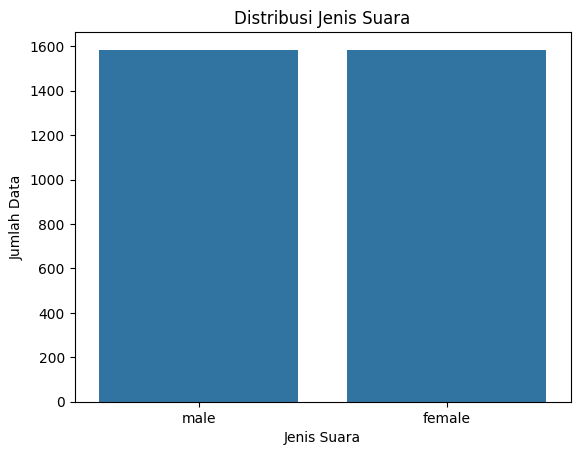

In [26]:
# Grafik jumlah data tiap kelas
sns.countplot(data=data, x='label')
plt.title('Distribusi Jenis Suara')
plt.xlabel('Jenis Suara')
plt.ylabel('Jumlah Data')
plt.show()

Selanjutnya, lihat distribusi beberapa fitur suara berdasarkan label.

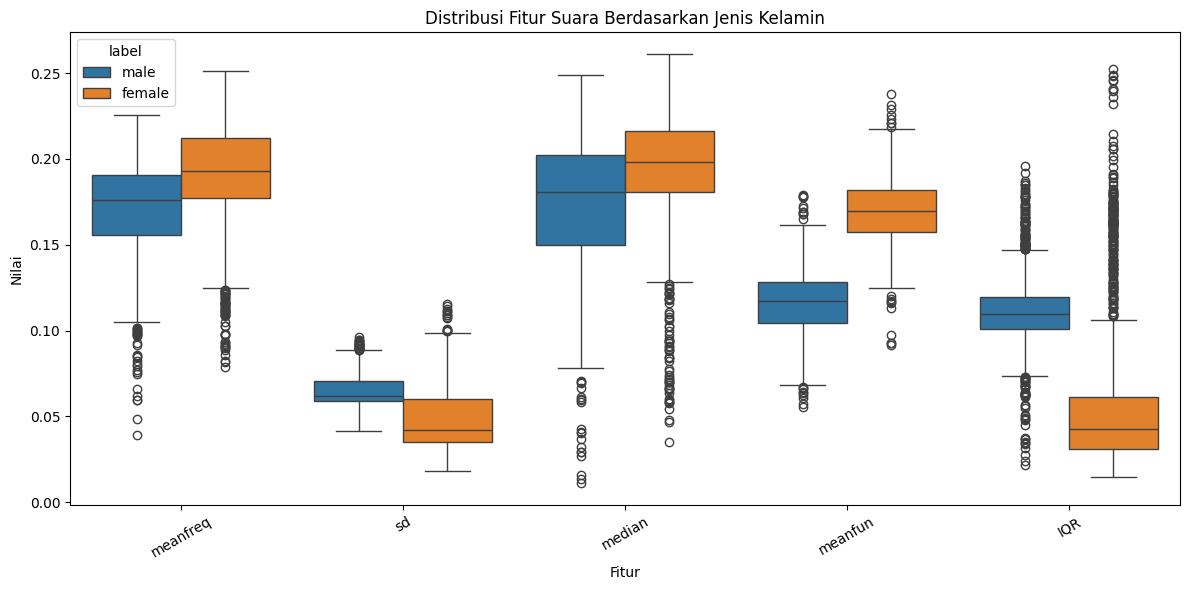

In [27]:
fitur_awal = ['meanfreq', 'sd', 'median', 'meanfun', 'IQR']

data_melt = data.melt(
    id_vars='label',
    value_vars=fitur_awal,
    var_name='Fitur',
    value_name='Nilai'
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=data_melt, x='Fitur', y='Nilai', hue='label')
plt.title('Distribusi Fitur Suara Berdasarkan Jenis Kelamin')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Preprocessing dan pembagian data

pisahkan fitur dan label, lalu membagi data menjadi 70% data latih dan 30% data uji serta melakukan standardisasi.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Menghapus baris yang memiliki nilai kosong
data = data.dropna().copy()

# Memisahkan fitur dan target
X = data.drop(columns=['label'])
y = data['label']

# Membagi data: 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# Standardisasi fitur
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Jumlah fitur awal:", X_train.shape[1])

Jumlah data training: 2217
Jumlah data testing: 951
Jumlah fitur awal: 20


Standardisasi diperlukan karena rentang nilai antarfitur suara bisa berbeda. Karena kNN menggunakan jarak, fitur dengan skala besar bisa mendominasi perhitungan apabila tidak distandardisasi.

Membuat model kNN awal

Sebelum mencari fitur dan nilai \(k\) terbaik, buat model awal dengan semua fitur dan \(k=3\)

In [29]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Membuat dan melatih model awal
knn_awal = KNeighborsClassifier(n_neighbors=3)
knn_awal.fit(X_train_scaled, y_train)

# Prediksi data testing
y_pred_awal = knn_awal.predict(X_test_scaled)

# Evaluasi
print("Akurasi awal:", accuracy_score(y_test, y_pred_awal))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_awal))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_awal))

Akurasi awal: 0.9737118822292324

Confusion Matrix:
[[462  14]
 [ 11 464]]

Classification Report:
              precision    recall  f1-score   support

      female       0.98      0.97      0.97       476
        male       0.97      0.98      0.97       475

    accuracy                           0.97       951
   macro avg       0.97      0.97      0.97       951
weighted avg       0.97      0.97      0.97       951



Percobaan untuk mencari fitur terbaik

Kita akan mengurutkan fitur berdasarkan informasi yang dimilikinya terhadap label, lalu menguji beberapa jumlah fitur menggunakan 5-fold cross-validation. Seluruh pemilihan fitur dilakukan pada data training agar data testing tidak bocor ke proses pemilihan.


a. Mengurutkan fitur

,Fitur,Skor Informasi
0,meanfun,0.552268
1,IQR,0.443463
2,Q25,0.405638
3,sd,0.302157
4,mode,0.182577
5,sp.ent,0.160691
6,sfm,0.132118
7,meanfreq,0.120140
8,centroid,0.120140
9,mindom,0.090520


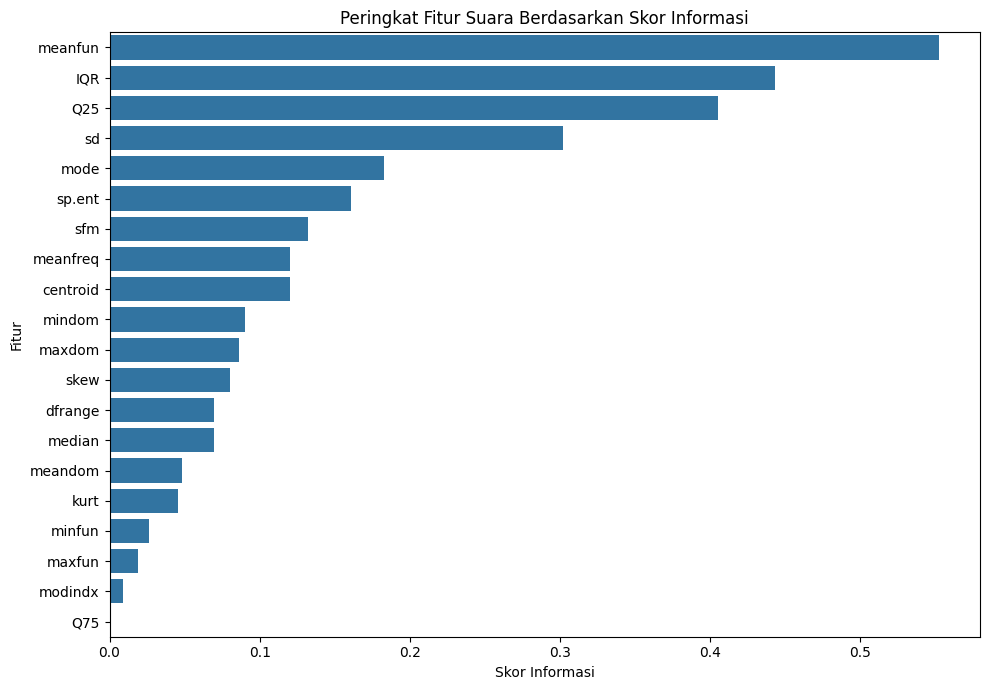

In [30]:
from sklearn.feature_selection import mutual_info_classif

# Mengukur informasi setiap fitur terhadap label
skor_fitur = mutual_info_classif(
    X_train,
    y_train,
    random_state=42
)

peringkat_fitur = pd.DataFrame({
    'Fitur': X_train.columns,
    'Skor Informasi': skor_fitur
}).sort_values(
    by='Skor Informasi',
    ascending=False
).reset_index(drop=True)

display(peringkat_fitur)

# Grafik peringkat fitur
plt.figure(figsize=(10, 7))
sns.barplot(
    data=peringkat_fitur,
    x='Skor Informasi',
    y='Fitur'
)
plt.title('Peringkat Fitur Suara Berdasarkan Skor Informasi')
plt.xlabel('Skor Informasi')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

b. Menguji kombinasi jumlah fitur

mencoba 2 fitur, 3 fitur, dan seterusnya sampai seluruh fitur tersedia. Model awal menggunakan \(k=3\), sedangkan nilai \(k\) akan dioptimalkan pada langkah berikutnya.

,Jumlah Fitur,Akurasi CV
3,5,0.977899
6,8,0.977899
7,9,0.976996
4,6,0.976543
5,7,0.976096
8,10,0.976096
9,11,0.976095
2,4,0.975644
10,12,0.975642
13,15,0.974291


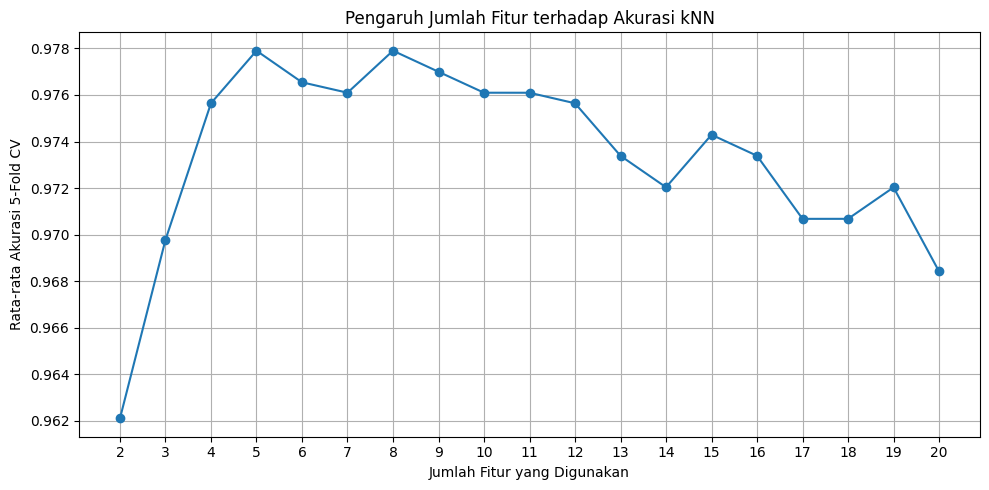

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Fitur diurutkan dari skor tertinggi
daftar_fitur = peringkat_fitur['Fitur'].tolist()

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

hasil_fitur = []

# Menguji jumlah fitur mulai dari 2 hingga semua fitur
for jumlah in range(2, len(daftar_fitur) + 1):
    fitur_dipakai = daftar_fitur[:jumlah]

    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=3))
    ])

    skor = cross_val_score(
        model,
        X_train[fitur_dipakai],
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    hasil_fitur.append({
        'Jumlah Fitur': jumlah,
        'Akurasi CV': skor.mean(),
        'Fitur': fitur_dipakai
    })

tabel_fitur = pd.DataFrame(hasil_fitur)

# Menampilkan hasil seluruh percobaan
display(
    tabel_fitur[['Jumlah Fitur', 'Akurasi CV']]
    .sort_values('Akurasi CV', ascending=False)
)

# Grafik jumlah fitur vs akurasi
plt.figure(figsize=(10, 5))
plt.plot(
    tabel_fitur['Jumlah Fitur'],
    tabel_fitur['Akurasi CV'],
    marker='o'
)
plt.title('Pengaruh Jumlah Fitur terhadap Akurasi kNN')
plt.xlabel('Jumlah Fitur yang Digunakan')
plt.ylabel('Rata-rata Akurasi 5-Fold CV')
plt.xticks(range(2, len(daftar_fitur) + 1))
plt.grid(True)
plt.tight_layout()
plt.show()

c. Menentukan fitur terpilih

In [32]:
# Memilih jumlah fitur dengan akurasi CV tertinggi
indeks_terbaik = tabel_fitur['Akurasi CV'].idxmax()
baris_terbaik = tabel_fitur.loc[indeks_terbaik]

jumlah_fitur_terbaik = int(baris_terbaik['Jumlah Fitur'])
fitur_terbaik = baris_terbaik['Fitur']

print("Jumlah fitur terbaik:", jumlah_fitur_terbaik)
print("Akurasi CV terbaik:", round(baris_terbaik['Akurasi CV'], 4))
print("Fitur yang dipilih:")
for fitur in fitur_terbaik:
    print("-", fitur)

Jumlah fitur terbaik: 5
Akurasi CV terbaik: 0.9779
Fitur yang dipilih:
- meanfun
- IQR
- Q25
- sd
- mode


Mencari nilai \(k\) terbaik

Kita akan menguji nilai \(k\) dari 1 sampai 31 menggunakan fitur terpilih pada langkah sebelumnya.

Nilai \(k\) terbaik ditentukan berdasarkan rata-rata akurasi 5-fold cross-validation pada data training, bukan sekadar memilih nilai dengan akurasi testing tertinggi.

In [33]:
hasil_k = []

X_train_pilih = X_train[fitur_terbaik]
X_test_pilih = X_test[fitur_terbaik]

# Menguji nilai K dari 1 sampai 31
for k in range(1, 32):
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])

    skor_cv = cross_val_score(
        model,
        X_train_pilih,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    hasil_k.append({
        'K': k,
        'Akurasi CV': skor_cv.mean()
    })

tabel_k = pd.DataFrame(hasil_k)

# Menampilkan hasil pengujian K
display(
    tabel_k.sort_values('Akurasi CV', ascending=False)
)

# Memilih K dengan akurasi CV tertinggi
baris_k_terbaik = tabel_k.loc[tabel_k['Akurasi CV'].idxmax()]
k_terbaik = int(baris_k_terbaik['K'])

print("Nilai K terbaik:", k_terbaik)
print("Akurasi CV terbaik:", round(baris_k_terbaik['Akurasi CV'], 4))

,K,Akurasi CV
3,4,0.977901
2,3,0.977899
4,5,0.977449
5,6,0.976998
7,8,0.976096
6,7,0.975193
1,2,0.974745
9,10,0.974743
8,9,0.972940
11,12,0.972939


Nilai K terbaik: 4
Akurasi CV terbaik: 0.9779


Grafik analisis nilai \(k\)

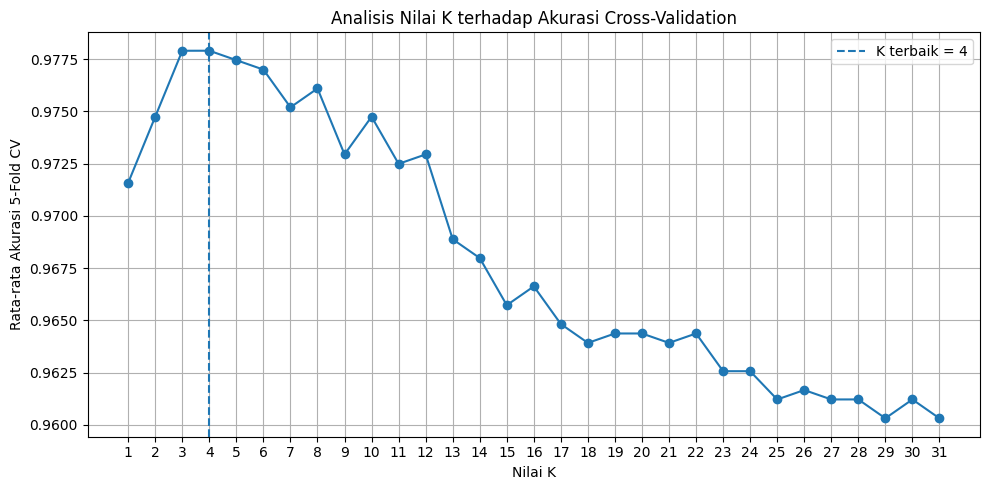

In [34]:
plt.figure(figsize=(10, 5))

plt.plot(
    tabel_k['K'],
    tabel_k['Akurasi CV'],
    marker='o'
)

plt.axvline(
    k_terbaik,
    linestyle='--',
    label=f'K terbaik = {k_terbaik}'
)

plt.title('Analisis Nilai K terhadap Akurasi Cross-Validation')
plt.xlabel('Nilai K')
plt.ylabel('Rata-rata Akurasi 5-Fold CV')
plt.xticks(range(1, 32))
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Evaluasi model akhir

Setelah mendapatkan fitur dan nilai \(k\) terbaik, latih model akhir lalu ukur akurasinya pada data training dan testing.


In [35]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Membuat model akhir menggunakan fitur dan K terpilih
model_akhir = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=k_terbaik))
])

model_akhir.fit(X_train_pilih, y_train)

# Prediksi data training dan testing
prediksi_train = model_akhir.predict(X_train_pilih)
prediksi_test = model_akhir.predict(X_test_pilih)

# Menghitung akurasi
akurasi_train = accuracy_score(y_train, prediksi_train)
akurasi_test = accuracy_score(y_test, prediksi_test)

print("Fitur terpilih:", list(fitur_terbaik))
print("Nilai K terbaik:", k_terbaik)
print(f"Akurasi training: {akurasi_train:.4f}")
print(f"Akurasi testing : {akurasi_test:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, prediksi_test))

print("\nClassification Report:")
print(classification_report(y_test, prediksi_test))

Fitur terpilih: ['meanfun', 'IQR', 'Q25', 'sd', 'mode']
Nilai K terbaik: 4
Akurasi training: 0.9838
Akurasi testing : 0.9821

Confusion Matrix:
[[471   5]
 [ 12 463]]

Classification Report:
              precision    recall  f1-score   support

      female       0.98      0.99      0.98       476
        male       0.99      0.97      0.98       475

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



Grafik perbandingan akurasi training dan testing

Grafik ini membantu melihat apakah performa model pada data latih dan data uji cukup berdekatan.

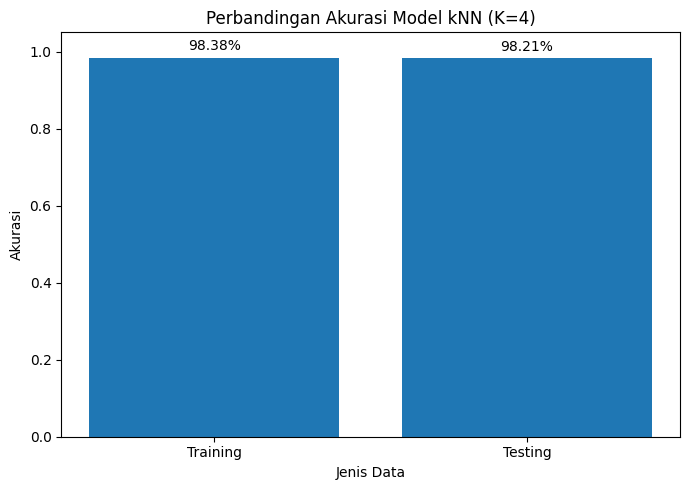

In [36]:
plt.figure(figsize=(7, 5))

plt.bar(
    ['Training', 'Testing'],
    [akurasi_train, akurasi_test]
)

plt.title(f'Perbandingan Akurasi Model kNN (K={k_terbaik})')
plt.xlabel('Jenis Data')
plt.ylabel('Akurasi')
plt.ylim(0, 1.05)

for i, nilai in enumerate([akurasi_train, akurasi_test]):
    plt.text(i, nilai + 0.02, f'{nilai:.2%}', ha='center')

plt.tight_layout()
plt.show()

**Analisa:**

1. Hasil klasifikasi jenis suara

Model k-Nearest Neighbors (kNN) digunakan untuk mengklasifikasikan jenis suara menjadi laki-laki (male) dan perempuan (female) berdasarkan karakteristik suara pada dataset voice.csv. Data dibagi menjadi data training sebesar 70% dan data testing sebesar 30%. Sebelum pelatihan, fitur suara distandardisasi agar perbedaan skala tidak mendominasi perhitungan jarak.

2. Hasil pemilihan fitur

Pemilihan fitur dilakukan dengan mengurutkan fitur berdasarkan skor informasi, kemudian menguji beberapa kombinasi jumlah fitur menggunakan metode 5-fold cross-validation. Berdasarkan hasil pengujian, diperoleh lima fitur terpilih, yaitu meanfun, IQR, Q25, sd, dan mode. Kelima fitur tersebut digunakan karena kombinasi jumlah fitur yang diuji memberikan rata-rata akurasi validasi terbaik. Fitur-fitur tersebut menjadi dasar model untuk membedakan karakteristik suara laki-laki dan perempuan.

3. Hasil penentuan nilai K

Penentuan nilai (K) dilakukan dengan menguji nilai (K) dari 1 hingga 31 menggunakan metode 5-fold cross-validation. Berdasarkan hasil pengujian, diperoleh nilai (K = 4) sebagai nilai terbaik di antara nilai yang diuji. Nilai ini dipilih karena menghasilkan rata-rata akurasi validasi tertinggi berdasarkan eksperimen. Nilai (K) yang terlalu kecil dapat membuat model lebih sensitif terhadap data di sekitarnya, sedangkan nilai yang terlalu besar dapat menyebabkan model kurang peka terhadap pola lokal. Grafik pengujian nilai (K) digunakan untuk memperlihatkan perbedaan akurasi pada setiap nilai yang diuji.

4. Evaluasi model akhir

Model kNN dengan lima fitur terpilih dan nilai (K = 4) memperoleh akurasi training sebesar 98,38% dan akurasi testing sebesar 98,21%. Selisih akurasi keduanya hanya 0,17 poin persentase. Hasil tersebut menunjukkan bahwa model memiliki performa yang tinggi dan relatif konsisten pada data training maupun testing.

Berdasarkan confusion matrix, dari 951 data testing, sebanyak 934 data berhasil diklasifikasikan dengan benar, sedangkan 17 data mengalami kesalahan klasifikasi. Sebanyak 471 data perempuan dan 463 data laki-laki berhasil diklasifikasikan dengan benar. Sementara itu, terdapat 5 data perempuan yang diprediksi sebagai laki-laki dan 12 data laki-laki yang diprediksi sebagai perempuan.

Hasil classification report menunjukkan bahwa kelas female memperoleh nilai precision sebesar 0,98, recall sebesar 0,99, dan F1-score sebesar 0,98. Sementara itu, kelas male memperoleh precision sebesar 0,99, recall sebesar 0,97, dan F1-score sebesar 0,98. Hasil tersebut menunjukkan bahwa model mampu mengklasifikasikan kedua kategori suara dengan baik, meskipun masih terdapat beberapa kesalahan prediksi.

## Tugas 2

Import library dan membaca dataset

In [37]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

data = pd.read_csv('/content/spam.csv', encoding='latin-1')

display(data.head())
print("Ukuran dataset:", data.shape)
print("Nama kolom:", data.columns.tolist())

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


Ukuran dataset: (5572, 5)
Nama kolom: ['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4']


Persiapan data

In [38]:
# Mengambil kolom label dan isi pesan
data = data[['v1', 'v2']].copy()
data.columns = ['label', 'pesan']

# Membagi data menjadi fitur dan target
X = data['pesan']
y = data['label']

# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 4457
Jumlah data testing: 1115


Model pertama: CountVectorizer

CountVectorizer mengubah pesan menjadi angka berdasarkan jumlah kemunculan kata.

In [39]:
# Mengubah teks menjadi hitungan kata
vectorizer_count = CountVectorizer(stop_words='english')

X_train_count = vectorizer_count.fit_transform(X_train)
X_test_count = vectorizer_count.transform(X_test)

# Melatih model Naive Bayes
model_count = MultinomialNB()
model_count.fit(X_train_count, y_train)

# Prediksi data testing
pred_count = model_count.predict(X_test_count)

# Evaluasi model
print("Akurasi CountVectorizer:",
      accuracy_score(y_test, pred_count))

print("\nClassification Report:")
print(classification_report(y_test, pred_count))

print("Confusion Matrix:")
print(confusion_matrix(y_test, pred_count))

Akurasi CountVectorizer: 0.9838565022421525

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.92      0.94       149

    accuracy                           0.98      1115
   macro avg       0.97      0.96      0.96      1115
weighted avg       0.98      0.98      0.98      1115

Confusion Matrix:
[[960   6]
 [ 12 137]]


Model kedua: TF-IDF

TF-IDF memberikan bobot pada kata berdasarkan tingkat kepentingannya dalam kumpulan pesan. Kata yang terlalu sering muncul di banyak pesan cenderung memperoleh bobot lebih rendah.

In [40]:
# Mengubah teks menjadi bobot TF-IDF
vectorizer_tfidf = TfidfVectorizer(stop_words='english')

X_train_tfidf = vectorizer_tfidf.fit_transform(X_train)
X_test_tfidf = vectorizer_tfidf.transform(X_test)

# Melatih model Naive Bayes
model_tfidf = MultinomialNB()
model_tfidf.fit(X_train_tfidf, y_train)

# Prediksi data testing
pred_tfidf = model_tfidf.predict(X_test_tfidf)

# Evaluasi model
print("Akurasi TF-IDF:",
      accuracy_score(y_test, pred_tfidf))

print("\nClassification Report:")
print(classification_report(y_test, pred_tfidf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, pred_tfidf))

Akurasi TF-IDF: 0.968609865470852

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.77      0.87       149

    accuracy                           0.97      1115
   macro avg       0.98      0.88      0.92      1115
weighted avg       0.97      0.97      0.97      1115

Confusion Matrix:
[[966   0]
 [ 35 114]]


Membandingkan hasil kedua model

,Metode,Akurasi
0,CountVectorizer,0.983857
1,TF-IDF,0.968610


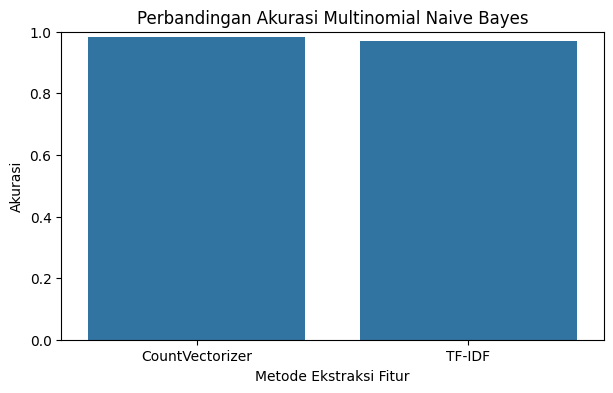

In [41]:
hasil = pd.DataFrame({
    'Metode': ['CountVectorizer', 'TF-IDF'],
    'Akurasi': [
        accuracy_score(y_test, pred_count),
        accuracy_score(y_test, pred_tfidf)
    ]
})

display(hasil)

plt.figure(figsize=(7, 4))
sns.barplot(data=hasil, x='Metode', y='Akurasi')
plt.title('Perbandingan Akurasi Multinomial Naive Bayes')
plt.ylim(0, 1)
plt.ylabel('Akurasi')
plt.xlabel('Metode Ekstraksi Fitur')
plt.show()

**Analisis dan kesimpulan**:

1. Hasil CountVectorizer

Model Multinomial Naive Bayes dengan CountVectorizer memperoleh akurasi sebesar 98,39%. Dari 1.115 data pengujian, sebanyak 1.097 data berhasil diklasifikasikan dengan benar dan 18 data salah diklasifikasikan. Model ini berhasil mengenali 137 dari 149 pesan spam dan 960 dari 966 pesan bukan spam (ham).

2. Hasil TF-IDF

Model Multinomial Naive Bayes dengan TF-IDF memperoleh akurasi sebesar 96,86%. Dari 1.115 data pengujian, sebanyak 1.080 data berhasil diklasifikasikan dengan benar dan 35 data salah diklasifikasikan. Model ini berhasil mengenali seluruh 966 pesan ham, tetapi hanya mendeteksi 114 dari 149 pesan spam.

3. Perbandingan dan Kesimpulan

Berdasarkan hasil pengujian, CountVectorizer memperoleh akurasi sebesar 98,39%, lebih tinggi daripada TF-IDF yang memperoleh 96,86%. CountVectorizer juga mampu mendeteksi lebih banyak pesan spam, yaitu 137 pesan, sedangkan TF-IDF hanya 114 pesan.

jadi, CountVectorizer merupakan metode yang lebih baik pada pengujian ini karena menghasilkan akurasi lebih tinggi dan lebih baik dalam mengenali pesan spam. Sementara itu, TF-IDF tidak salah mengklasifikasikan pesan ham sebagai spam, tetapi masih melewatkan lebih banyak pesan spam.